In [ ]:
install.packages('caret')

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘sparsevctrs’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘pROC’, ‘recipes’, ‘reshape2’




In [ ]:
library(caret)
library(tidyverse)
library(data.table)

# **데이터 로드**

In [ ]:
# https://drive.google.com/file/d/1hMjL7QXl7wckG49IBdhEleDvG-kBn6yF/view?usp=sharing
system("gdown --id 1hMjL7QXl7wckG49IBdhEleDvG-kBn6yF") # 계정공유
system("ls", TRUE) # 파일 확인

[1] "England_PremierLeague.csv" "sample_data"

In [ ]:
# PL_raw에 tibble 형태로 읽어 들여 확인
PL_raw <- fread("England_PremierLeague.csv")
PL_raw <- as_tibble(PL_raw)

head(PL_raw, 2)

Date,Season,HomeTeam,AwayTeam,FTH Goals,FTA Goals,FT Result,HTH Goals,HTA Goals,HT Result,⋯,H Fouls,A Fouls,H Corners,A Corners,H Yellow,A Yellow,H Red,A Red,Display_Order,League
<chr>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<int>,<int>,<chr>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>
16/01/2025,2024/25,Ipswich Town,Brighton & Hove Albion,0,2,A,0,1,A,⋯,13,14,1,9,2,2,0,0,20250116,Premier League
16/01/2025,2024/25,Man United,Southampton,3,1,H,0,1,A,⋯,7,10,4,4,1,3,0,0,20250116,Premier League


# 데이터 전처리

In [ ]:
# 자료형 확인
PL_raw %>% str()

tibble [12,153 × 25] (S3: tbl_df/tbl/data.frame)
 $ Date         : chr [1:12153] "16/01/2025" "16/01/2025" "15/01/2025" "15/01/2025" ...
 $ Season       : chr [1:12153] "2024/25" "2024/25" "2024/25" "2024/25" ...
 $ HomeTeam     : chr [1:12153] "Ipswich Town" "Man United" "Everton" "Leicester" ...
 $ AwayTeam     : chr [1:12153] "Brighton & Hove Albion" "Southampton" "Aston Villa" "Crystal Palace" ...
 $ FTH Goals    : int [1:12153] 0 3 0 0 3 2 2 2 3 1 ...
 $ FTA Goals    : int [1:12153] 2 1 1 2 0 1 2 2 2 1 ...
 $ FT Result    : chr [1:12153] "A" "H" "A" "A" ...
 $ HTH Goals    : int [1:12153] 0 0 0 0 1 2 0 1 2 1 ...
 $ HTA Goals    : int [1:12153] 1 1 0 0 0 1 0 0 0 0 ...
 $ HT Result    : chr [1:12153] "A" "A" "D" "D" ...
 $ Referee      : chr [1:12153] "T Harrington" "J Brooks" "S Barrott" "A Madley" ...
 $ H Shots      : int [1:12153] 5 23 10 21 17 14 18 26 4 6 ...
 $ A Shots      : int [1:12153] 11 13 11 9 13 10 21 7 21 23 ...
 $ H SOT        : int [1:12153] 3 9 3 4 5 4 6 10 3 3 ..

In [ ]:
# 변수 이름 공백 지우기
names(PL_raw) <- gsub(" ", "_", names(PL_raw))

PL_raw %>% str()

tibble [12,153 × 25] (S3: tbl_df/tbl/data.frame)
 $ Date         : chr [1:12153] "16/01/2025" "16/01/2025" "15/01/2025" "15/01/2025" ...
 $ Season       : chr [1:12153] "2024/25" "2024/25" "2024/25" "2024/25" ...
 $ HomeTeam     : chr [1:12153] "Ipswich Town" "Man United" "Everton" "Leicester" ...
 $ AwayTeam     : chr [1:12153] "Brighton & Hove Albion" "Southampton" "Aston Villa" "Crystal Palace" ...
 $ FTH_Goals    : int [1:12153] 0 3 0 0 3 2 2 2 3 1 ...
 $ FTA_Goals    : int [1:12153] 2 1 1 2 0 1 2 2 2 1 ...
 $ FT_Result    : chr [1:12153] "A" "H" "A" "A" ...
 $ HTH_Goals    : int [1:12153] 0 0 0 0 1 2 0 1 2 1 ...
 $ HTA_Goals    : int [1:12153] 1 1 0 0 0 1 0 0 0 0 ...
 $ HT_Result    : chr [1:12153] "A" "A" "D" "D" ...
 $ Referee      : chr [1:12153] "T Harrington" "J Brooks" "S Barrott" "A Madley" ...
 $ H_Shots      : int [1:12153] 5 23 10 21 17 14 18 26 4 6 ...
 $ A_Shots      : int [1:12153] 11 13 11 9 13 10 21 7 21 23 ...
 $ H_SOT        : int [1:12153] 3 9 3 4 5 4 6 10 3 3 ..

In [ ]:
# 불필요한 변수 제거
PL <- PL_raw %>%
  select(-Date, -Season, -Display_Order, -League, -HomeTeam, -AwayTeam, -Referee, -FTA_Goals, -FTH_Goals)

In [ ]:
# FT_Result 구조 확인
unique(PL$FT_Result)

[1] "A" "H" "D"

In [ ]:
# 홈팀 승리(H) = 2, 무승부(D) = 1, 원정팀 승리(A) = 0 으로 변환
PL$FT_Result <- ifelse(PL$FT_Result == "A", 0,
                           ifelse(PL$FT_Result == "D", 1, 2))

table(PL$FT_Result)


   0    1    2 
3482 3108 5563 

In [ ]:
# 팩터 변수 변환
PL <- PL %>%
  mutate(FT_Result = factor(FT_Result))

#확인
PL %>% str()

tibble [12,153 × 16] (S3: tbl_df/tbl/data.frame)
 $ FT_Result: Factor w/ 3 levels "0","1","2": 1 3 1 1 3 3 2 2 3 2 ...
 $ HTH_Goals: int [1:12153] 0 0 0 0 1 2 0 1 2 1 ...
 $ HTA_Goals: int [1:12153] 1 1 0 0 0 1 0 0 0 0 ...
 $ HT_Result: chr [1:12153] "A" "A" "D" "D" ...
 $ H_Shots  : int [1:12153] 5 23 10 21 17 14 18 26 4 6 ...
 $ A_Shots  : int [1:12153] 11 13 11 9 13 10 21 7 21 23 ...
 $ H_SOT    : int [1:12153] 3 9 3 4 5 4 6 10 3 3 ...
 $ A_SOT    : int [1:12153] 5 5 3 4 7 2 8 3 5 7 ...
 $ H_Fouls  : int [1:12153] 13 7 17 7 10 16 4 15 9 7 ...
 $ A_Fouls  : int [1:12153] 14 10 10 6 13 9 4 16 18 10 ...
 $ H_Corners: int [1:12153] 1 4 8 4 4 10 4 9 0 0 ...
 $ A_Corners: int [1:12153] 9 4 5 3 2 4 5 3 3 9 ...
 $ H_Yellow : int [1:12153] 2 1 2 0 0 3 0 2 3 2 ...
 $ A_Yellow : int [1:12153] 2 3 1 0 2 1 0 3 3 1 ...
 $ H_Red    : int [1:12153] 0 0 0 0 0 0 0 0 0 0 ...
 $ A_Red    : int [1:12153] 0 0 0 0 0 0 0 0 0 0 ...


In [ ]:
# NA 확인
table(is.na(PL))


 FALSE   TRUE 
158712  35736 

In [ ]:
# NA가 포함된 행 제거
PL <- na.omit(PL)

# 확인
table(is.na(PL))

cat("행 개수 : ", nrow(PL))


 FALSE 
149264 

행 개수 :  9329

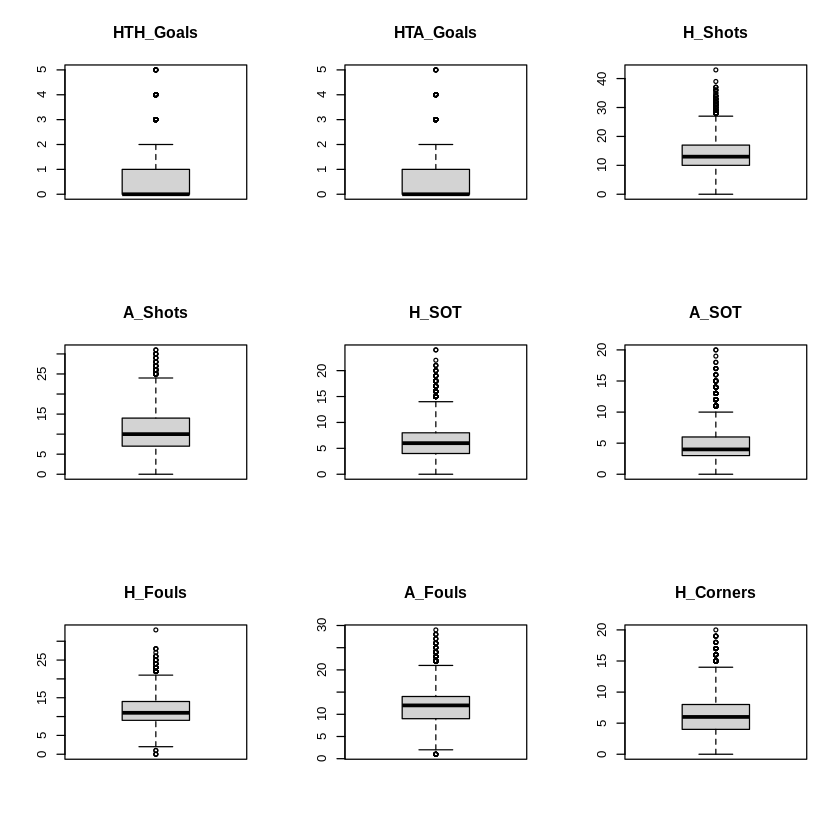

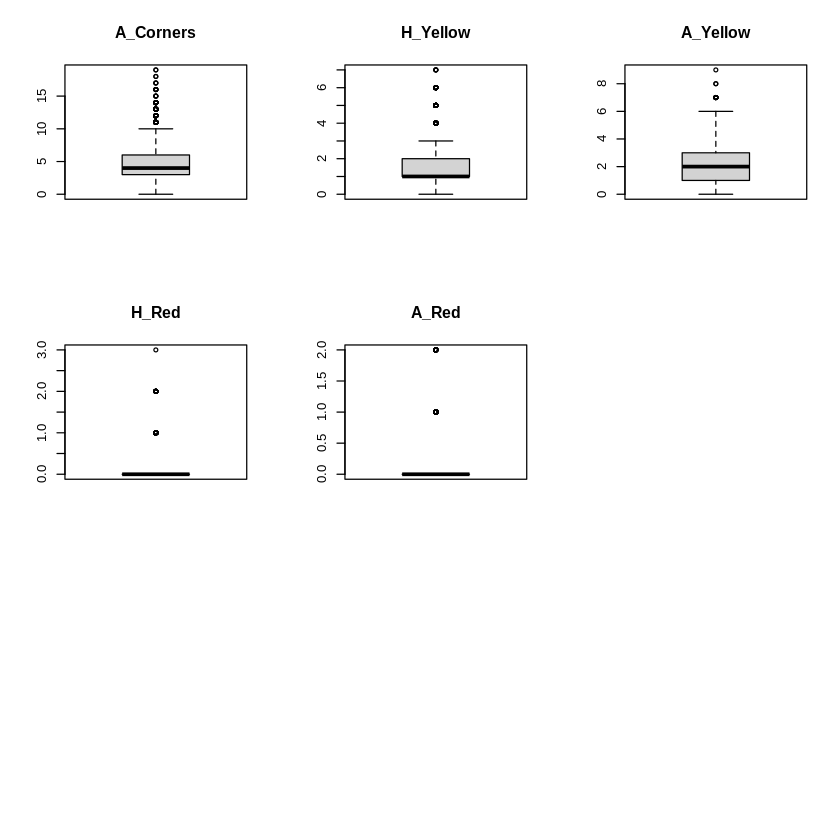

In [ ]:
# 수치형 변수만 선택
numeric_cols <- names(PL)[sapply(PL, is.numeric)]

# 박스 플롯
par(mfrow = c(3, 3))
for (col in numeric_cols) {
  boxplot(PL[[col]], main = col)
}

# RandomForest 모델 생성

In [ ]:
install.packages("randomForest")
library(randomForest)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:dplyr’:

    combine


The following object is masked from ‘package:ggplot2’:

    margin




In [ ]:
# PL 데이터를 PL$FT_Result 기준으로 90%는 학습 데이터(train_PL)로, 나머지는 테스트 데이터(test_PL)로 분리

# 재현 가능성을 위해 시드 고정
set.seed(123)

# FT_Result 기준으로 90% 학습용 인덱스 생성
train_index <- createDataPartition(PL$FT_Result, p = 0.9, list = FALSE)

# 데이터 분리
train_PL <- PL[train_index, ]
test_PL  <- PL[-train_index, ]

# 확인
cat("학습 데이터 개수 : ", nrow(train_PL), "\n")
cat("테스트 데이터 개수 : ", nrow(test_PL))

학습 데이터 개수 :  8398 
테스트 데이터 개수 :  931

In [ ]:
# train_PL 이용하여 Random Forest 모델 rfm_PL 생성하고 확인

# 재현 가능성을 위해 시드 고정
set.seed(123)

# 모델 생성
rfm_PL <- randomForest(FT_Result ~ .,
                       data = train_PL,
                       ntree = 1000,
                       mtry = 3,
                       classwt = c("0" = 1, "1" = 2, "2" = 1)
                       )

# 모델 확인
rfm_PL


Call:
 randomForest(formula = FT_Result ~ ., data = train_PL, ntree = 1000,      mtry = 3, classwt = c(`0` = 1, `1` = 2, `2` = 1)) 
               Type of random forest: classification
                     Number of trees: 1000
No. of variables tried at each split: 3

        OOB estimate of  error rate: 36.66%
Confusion matrix:
     0   1    2 class.error
0 1674 460  331   0.3208925
1  598 614  870   0.7050913
2  296 524 3031   0.2129317

# 예측

In [ ]:
# 모델 rfm_PL 을 사용하여 test_PL 데이터로 예측을 수행한 후 예측값을 predict_value_rf 에 저장하고 확인

# 예측 수행
predict_value_rf <-
  predict(rfm_PL, test_PL, type = "class") %>%
    tibble(predict_value_rf = .)

# 예측 결과 확인
predict_value_rf %>% show()

# A tibble: 931 × 1
   predict_value_rf
   <fct>           
 1 1               
 2 0               
 3 1               
 4 0               
 5 0               
 6 0               
 7 0               
 8 2               
 9 0               
10 2               
# ℹ 921 more rows


In [ ]:
# test_PL 데이터의 FT_Result 데이터와 위에서 구한 predict_value_rf를 묶어 real_predict_rf에 저장하고 확인

# test_PL에서 실제 FT_Result 열 선택
real_predict_rf <-
  test_PL %>%
  select(FT_Result) %>%
  bind_cols(., predict_value_rf)    # 예측값 추가

# 결과 확인
real_predict_rf %>% show()

# A tibble: 931 × 2
   FT_Result predict_value_rf
   <fct>     <fct>           
 1 0         1               
 2 1         0               
 3 1         1               
 4 0         0               
 5 2         0               
 6 1         0               
 7 2         0               
 8 2         2               
 9 2         0               
10 2         2               
# ℹ 921 more rows


## 성능 확인

In [ ]:
# real_predict_rf에 저장된 FT_Result와 predict_value_rf 사이의 confusionMatrix를 생성한 후 정확도 및 성능지표를 확인

# confusionMatrix를 이용해 성능 평가
cm_rf <-
  confusionMatrix(real_predict_rf$FT_Result, real_predict_rf$predict_value_rf)

cm_rf

Confusion Matrix and Statistics

          Reference
Prediction   0   1   2
         0 185  41  47
         1  63  83  85
         2  42  57 328

Overall Statistics
                                          
               Accuracy : 0.6402          
                 95% CI : (0.6084, 0.6711)
    No Information Rate : 0.4941          
    P-Value [Acc > NIR] : < 2e-16         
                                          
                  Kappa : 0.4323          
                                          
 Mcnemar's Test P-Value : 0.01506         

Statistics by Class:

                     Class: 0 Class: 1 Class: 2
Sensitivity            0.6379  0.45856   0.7130
Specificity            0.8627  0.80267   0.7898
Pos Pred Value         0.6777  0.35931   0.7681
Neg Pred Value         0.8404  0.86000   0.7381
Prevalence             0.3115  0.19441   0.4941
Detection Rate         0.1987  0.08915   0.3523
Detection Prevalence   0.2932  0.24812   0.4586
Balanced Accuracy      0.7503  0.63062   

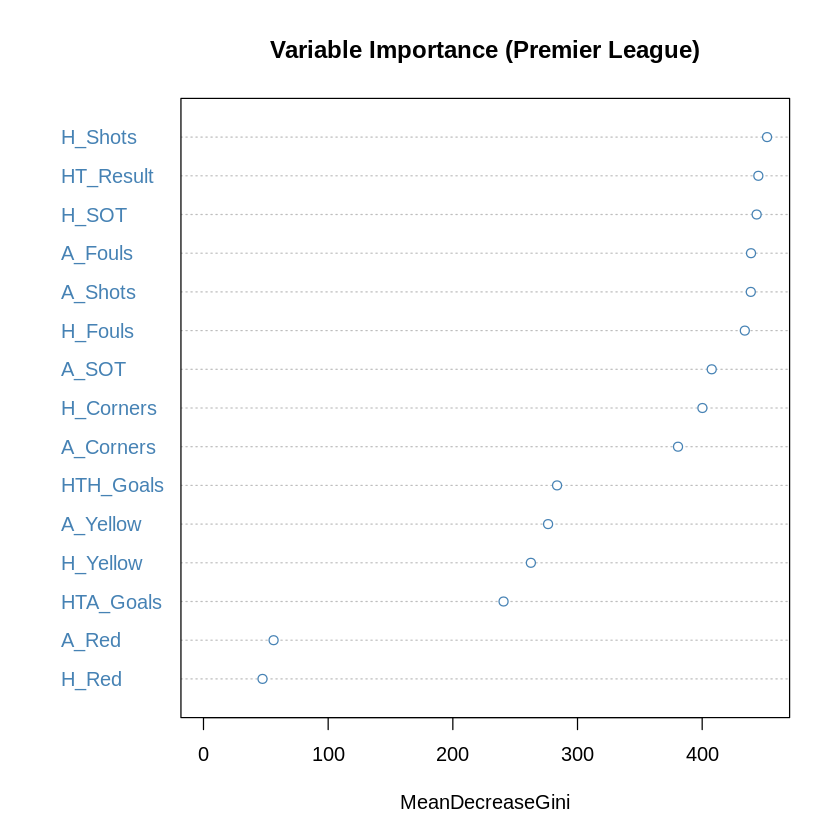

In [ ]:
# rfm_PL의 변수 중요도를 그림으로 나타낸 후 성능에 가장 큰 영향을 미치는 설명변수를 확인

# 변수 중요도 시각화
varImpPlot(rfm_PL,
           main = "Variable Importance (Premier League)",
           col = "steelblue")

In [ ]:
# importance() 함수로 중요도 추출
var_imp <- importance(rfm_PL)

In [ ]:
# 데이터프레임으로 변환
var_imp_df <- data.frame(
  Variable = rownames(var_imp),
  MeanDecreaseGini = var_imp[, "MeanDecreaseGini"]
)

In [ ]:
# 중요도 높은 순으로 정렬
var_imp_df <- var_imp_df %>% arrange(desc(MeanDecreaseGini))

In [ ]:
# 출력
print(var_imp_df)

           Variable MeanDecreaseGini
H_Shots     H_Shots        452.03713
HT_Result HT_Result        445.03912
H_SOT         H_SOT        443.68663
A_Fouls     A_Fouls        439.17201
A_Shots     A_Shots        438.98542
H_Fouls     H_Fouls        434.19874
A_SOT         A_SOT        407.65134
H_Corners H_Corners        400.18500
A_Corners A_Corners        380.61381
HTH_Goals HTH_Goals        283.60468
A_Yellow   A_Yellow        276.39433
H_Yellow   H_Yellow        262.59402
HTA_Goals HTA_Goals        240.67801
A_Red         A_Red         56.22889
H_Red         H_Red         47.35228


# 중요도 낮은 변수 제거하고 모델링

In [ ]:
set.seed(123)

# 변수 중요도 상위 9개 변수만 사용
rfm_PL_reduced <- randomForest(
  FT_Result ~ H_Shots + HT_Result + H_SOT + A_Fouls + A_Shots + H_Fouls + A_SOT + H_Corners + A_Corners,
  data = train_PL,
  ntree = 1000,
  mtry = 3
)

rfm_PL_reduced


Call:
 randomForest(formula = FT_Result ~ H_Shots + HT_Result + H_SOT +      A_Fouls + A_Shots + H_Fouls + A_SOT + H_Corners + A_Corners,      data = train_PL, ntree = 1000, mtry = 3) 
               Type of random forest: classification
                     Number of trees: 1000
No. of variables tried at each split: 3

        OOB estimate of  error rate: 36.71%
Confusion matrix:
     0   1    2 class.error
0 1700 374  391   0.3103448
1  631 526  925   0.7473583
2  325 437 3089   0.1978707

In [ ]:
predict_value_rf_reduced <-
  predict(rfm_PL_reduced, test_PL, type = "class") %>%
    tibble(predict_value_rf_reduced = .)

predict_value_rf_reduced %>% show()

# A tibble: 931 × 1
   predict_value_rf_reduced
   <fct>                   
 1 1                       
 2 0                       
 3 1                       
 4 0                       
 5 0                       
 6 0                       
 7 0                       
 8 2                       
 9 0                       
10 2                       
# ℹ 921 more rows


In [ ]:
# test_PL에서 실제 FT_Result 열 선택
real_predict_rf_reduced <-
  test_PL %>%
  select(FT_Result) %>%
  bind_cols(., predict_value_rf_reduced)    # 예측값 추가

# 결과 확인
real_predict_rf_reduced %>% show()

# A tibble: 931 × 2
   FT_Result predict_value_rf_reduced
   <fct>     <fct>                   
 1 0         1                       
 2 1         0                       
 3 1         1                       
 4 0         0                       
 5 2         0                       
 6 1         0                       
 7 2         0                       
 8 2         2                       
 9 2         0                       
10 2         2                       
# ℹ 921 more rows


In [ ]:
# real_predict_rf_reduced 에 저장된 FT_Result와 predict_value_rf_reduced 사이의 confusionMatrix를 생성한 후 정확도 및 성능지표를 확인

# confusionMatrix를 이용해 성능 평가
cm_rf_reduced <-
  confusionMatrix(real_predict_rf_reduced$FT_Result, real_predict_rf_reduced$predict_value_rf_reduced)

cm_rf_reduced

Confusion Matrix and Statistics

          Reference
Prediction   0   1   2
         0 186  39  48
         1  71  62  98
         2  44  47 336

Overall Statistics
                                          
               Accuracy : 0.6273          
                 95% CI : (0.5953, 0.6584)
    No Information Rate : 0.5177          
    P-Value [Acc > NIR] : 1.036e-11       
                                          
                  Kappa : 0.4068          
                                          
 Mcnemar's Test P-Value : 4.805e-06       

Statistics by Class:

                     Class: 0 Class: 1 Class: 2
Sensitivity            0.6179   0.4189   0.6971
Specificity            0.8619   0.7842   0.7973
Pos Pred Value         0.6813   0.2684   0.7869
Neg Pred Value         0.8252   0.8771   0.7103
Prevalence             0.3233   0.1590   0.5177
Detection Rate         0.1998   0.0666   0.3609
Detection Prevalence   0.2932   0.2481   0.4586
Balanced Accuracy      0.7399   0.6015   

# SVM

In [ ]:
install.packages("e1071")
library(e1071)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


Attaching package: ‘e1071’


The following object is masked from ‘package:ggplot2’:

    element




In [ ]:
set.seed(123)

# 모델 생성
svm_PL <- svm(
  FT_Result ~ .,
  data = train_PL,
  type = "C-classification",
  kernel = "radial",
  cost = 1,
  gamma = 0.01,
  probability = TRUE
)

# 예측
svm_pred <- predict(svm_PL, newdata = test_PL, type = "response")

# 혼동행렬
confusionMatrix(svm_pred, test_PL$FT_Result)


Confusion Matrix and Statistics

          Reference
Prediction   0   1   2
         0 174  53  28
         1  59  86  68
         2  40  92 331

Overall Statistics
                                          
               Accuracy : 0.6348          
                 95% CI : (0.6029, 0.6658)
    No Information Rate : 0.4586          
    P-Value [Acc > NIR] : <2e-16          
                                          
                  Kappa : 0.4247          
                                          
 Mcnemar's Test P-Value : 0.1097          

Statistics by Class:

                     Class: 0 Class: 1 Class: 2
Sensitivity            0.6374  0.37229   0.7752
Specificity            0.8769  0.81857   0.7381
Pos Pred Value         0.6824  0.40376   0.7149
Neg Pred Value         0.8536  0.79805   0.7949
Prevalence             0.2932  0.24812   0.4586
Detection Rate         0.1869  0.09237   0.3555
Detection Prevalence   0.2739  0.22879   0.4973
Balanced Accuracy      0.7571  0.59543   

# 예측 데이터셋 로드

In [ ]:
# https://drive.google.com/file/d/1T3_FX7X4TBn5X6mJw9gw1609PcB3Jt8-/view?usp=sharing
system("gdown --id 1T3_FX7X4TBn5X6mJw9gw1609PcB3Jt8-") # 계정공유
system("ls", TRUE) # 파일 확인

[1] "England_Championship.csv"  "England_PremierLeague.csv"
[3] "sample_data"

In [ ]:
# PL_raw에 tibble 형태로 읽어 들여 확인
PL2_raw <- fread("England_Championship.csv")
PL2_raw <- as_tibble(PL2_raw)

head(PL2_raw, 2)

Date,Season,HomeTeam,AwayTeam,FTH Goals,FTA Goals,FT Result,HTH Goals,HTA Goals,HT Result,⋯,H Fouls,A Fouls,H Corners,A Corners,H Yellow,A Yellow,H Red,A Red,Display_Order,League
<chr>,<chr>,<chr>,<chr>,<int>,<int>,<chr>,<int>,<int>,<chr>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>
15/01/2025,2024/25,Blackburn,Portsmouth,3,0,H,0,0,D,⋯,15,19,5,6,1,3,0,0,20250115,English Second
14/01/2025,2024/25,Cardiff,Watford,1,1,D,0,0,D,⋯,8,14,7,3,1,2,0,0,20250114,English Second


# 예측 데이터 전처리

In [ ]:
# 자료형 확인
PL2_raw %>% str()

tibble [11,351 × 25] (S3: tbl_df/tbl/data.frame)
 $ Date         : chr [1:11351] "15/01/2025" "14/01/2025" "14/01/2025" "6/01/2025" ...
 $ Season       : chr [1:11351] "2024/25" "2024/25" "2024/25" "2024/25" ...
 $ HomeTeam     : chr [1:11351] "Blackburn" "Cardiff" "Plymouth" "QPR" ...
 $ AwayTeam     : chr [1:11351] "Portsmouth" "Watford" "Oxford" "Luton" ...
 $ FTH Goals    : int [1:11351] 3 1 1 2 1 0 0 1 1 3 ...
 $ FTA Goals    : int [1:11351] 0 1 1 1 0 1 0 1 0 3 ...
 $ FT Result    : chr [1:11351] "H" "D" "D" "H" ...
 $ HTH Goals    : int [1:11351] 0 0 0 1 1 0 0 0 1 1 ...
 $ HTA Goals    : int [1:11351] 0 0 1 1 0 0 0 0 0 0 ...
 $ HT Result    : chr [1:11351] "D" "D" "A" "D" ...
 $ Referee      : chr [1:11351] "F Hallam" "O Langford" "S Allison" "A Davies" ...
 $ H Shots      : int [1:11351] 13 12 11 15 24 11 18 11 11 15 ...
 $ A Shots      : int [1:11351] 11 4 8 18 6 4 2 16 9 17 ...
 $ H SOT        : int [1:11351] 6 4 2 6 8 1 3 2 2 6 ...
 $ A SOT        : int [1:11351] 2 2 3 4 1 2 

In [ ]:
# 변수 이름 공백 지우기
names(PL2_raw) <- gsub(" ", "_", names(PL_raw))

PL2_raw %>% str()

tibble [11,351 × 25] (S3: tbl_df/tbl/data.frame)
 $ Date         : chr [1:11351] "15/01/2025" "14/01/2025" "14/01/2025" "6/01/2025" ...
 $ Season       : chr [1:11351] "2024/25" "2024/25" "2024/25" "2024/25" ...
 $ HomeTeam     : chr [1:11351] "Blackburn" "Cardiff" "Plymouth" "QPR" ...
 $ AwayTeam     : chr [1:11351] "Portsmouth" "Watford" "Oxford" "Luton" ...
 $ FTH_Goals    : int [1:11351] 3 1 1 2 1 0 0 1 1 3 ...
 $ FTA_Goals    : int [1:11351] 0 1 1 1 0 1 0 1 0 3 ...
 $ FT_Result    : chr [1:11351] "H" "D" "D" "H" ...
 $ HTH_Goals    : int [1:11351] 0 0 0 1 1 0 0 0 1 1 ...
 $ HTA_Goals    : int [1:11351] 0 0 1 1 0 0 0 0 0 0 ...
 $ HT_Result    : chr [1:11351] "D" "D" "A" "D" ...
 $ Referee      : chr [1:11351] "F Hallam" "O Langford" "S Allison" "A Davies" ...
 $ H_Shots      : int [1:11351] 13 12 11 15 24 11 18 11 11 15 ...
 $ A_Shots      : int [1:11351] 11 4 8 18 6 4 2 16 9 17 ...
 $ H_SOT        : int [1:11351] 6 4 2 6 8 1 3 2 2 6 ...
 $ A_SOT        : int [1:11351] 2 2 3 4 1 2 

In [ ]:
# 불필요한 변수 제거
PL2 <- PL2_raw %>%
  select(-Date, -Season, -Display_Order, -League, -HomeTeam, -AwayTeam, -Referee, -FTA_Goals, -FTH_Goals)

In [ ]:
# FT_Result 구조 확인
unique(PL2$FT_Result)

[1] "H" "D" "A"

In [ ]:
# 홈팀 승리(H) = 2, 무승부(D) = 1, 원정팀 승리(A) = 0 으로 변환
PL2$FT_Result <- ifelse(PL2$FT_Result == "A", 0,
                           ifelse(PL2$FT_Result == "D", 1, 2))

table(PL2$FT_Result)


   0    1    2 
3300 3125 4926 

In [ ]:
# 팩터 변수 변환
PL2 <- PL2 %>%
  mutate(FT_Result = factor(FT_Result))

#확인
PL2 %>% str()

tibble [11,351 × 16] (S3: tbl_df/tbl/data.frame)
 $ FT_Result: Factor w/ 3 levels "0","1","2": 3 2 2 3 3 1 2 2 3 2 ...
 $ HTH_Goals: int [1:11351] 0 0 0 1 1 0 0 0 1 1 ...
 $ HTA_Goals: int [1:11351] 0 0 1 1 0 0 0 0 0 0 ...
 $ HT_Result: chr [1:11351] "D" "D" "A" "D" ...
 $ H_Shots  : int [1:11351] 13 12 11 15 24 11 18 11 11 15 ...
 $ A_Shots  : int [1:11351] 11 4 8 18 6 4 2 16 9 17 ...
 $ H_SOT    : int [1:11351] 6 4 2 6 8 1 3 2 2 6 ...
 $ A_SOT    : int [1:11351] 2 2 3 4 1 2 1 4 3 9 ...
 $ H_Fouls  : int [1:11351] 15 8 8 10 9 16 13 6 7 14 ...
 $ A_Fouls  : int [1:11351] 19 14 10 9 10 18 11 8 12 9 ...
 $ H_Corners: int [1:11351] 5 7 6 3 7 10 6 5 6 5 ...
 $ A_Corners: int [1:11351] 6 3 3 4 3 0 3 6 7 7 ...
 $ H_Yellow : int [1:11351] 1 1 1 1 1 2 1 2 3 0 ...
 $ A_Yellow : int [1:11351] 3 2 1 1 2 2 2 4 1 1 ...
 $ H_Red    : int [1:11351] 0 0 0 0 0 0 0 0 0 0 ...
 $ A_Red    : int [1:11351] 0 0 0 0 1 0 0 0 0 0 ...


In [ ]:
# NA 확인
table(is.na(PL2))


 FALSE   TRUE 
181602     14 

In [ ]:
# NA가 포함된 행 제거
PL2 <- na.omit(PL2)

# 확인
table(is.na(PL2))

cat("행 개수 : ", nrow(PL2))


 FALSE 
181600 

행 개수 :  11350

In [ ]:
# 예측을 수행해야 하므로 FT_Result 제거
PL2_test <- PL2 %>%
  select(-FT_Result)

# 챔피언십 데이터 예측 - 랜덤 포레스트

In [ ]:
# 모델 rfm_PL 을 사용하여 PL2_test 데이터로 예측을 수행한 후 예측값을 predict_value 에 저장하고 확인
set.seed(123)

# 예측 수행
predict_value <- predict(rfm_PL, newdata = PL2_test)

# 예측 결과 확인
head(predict_value)

1 2 3 4 5 6 
2 1 0 2 2 1 
Levels: 0 1 2

In [ ]:
# PL2 데이터의 FT_Result 와 위에서 구한 predict_value 를 묶어 real_predict 티블에 저장하고 확인

# FT_Result 열만 선택 후 예측값과 묶기
real_predict <- PL2 %>%
  select(FT_Result) %>%
  bind_cols(tibble(predict_value = predict_value))

# 결과 확인
real_predict %>% show()

# A tibble: 11,350 × 2
   FT_Result predict_value
   <fct>     <fct>        
 1 2         2            
 2 1         1            
 3 1         0            
 4 2         2            
 5 2         2            
 6 0         1            
 7 1         1            
 8 1         0            
 9 2         2            
10 1         2            
# ℹ 11,340 more rows


# 예측 정확도 및 성능지표 확인

In [ ]:
# real_predict 의 FT_Result 와 predict_value 사이의 confusionMatrix 를 생성한 후 정확도 및 성능지표 확인

# 혼동행렬 생성
cm_PL <- confusionMatrix(real_predict$predict_value, real_predict$FT_Result)

# 결과 확인
cm_PL

Confusion Matrix and Statistics

          Reference
Prediction    0    1    2
         0 2138  821  425
         1  702 1085  822
         2  459 1219 3679

Overall Statistics
                                          
               Accuracy : 0.6081          
                 95% CI : (0.5991, 0.6171)
    No Information Rate : 0.434           
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.3926          
                                          
 Mcnemar's Test P-Value : < 2.2e-16       

Statistics by Class:

                     Class: 0 Class: 1 Class: 2
Sensitivity            0.6481  0.34720   0.7469
Specificity            0.8452  0.81471   0.7388
Pos Pred Value         0.6318  0.41587   0.6868
Neg Pred Value         0.8543  0.76662   0.7919
Prevalence             0.2907  0.27533   0.4340
Detection Rate         0.1884  0.09559   0.3241
Detection Prevalence   0.2981  0.22987   0.4720
Balanced Accuracy      0.7467

# 25-26 프리미어리그 12,13 라운드 예측

In [ ]:
# https://drive.google.com/file/d/1MUfrulYqtZxbvO4VLYitjpo4O2o2d6Ah/view?usp=sharing
system("gdown --id 1MUfrulYqtZxbvO4VLYitjpo4O2o2d6Ah") # 계정공유
system("ls", TRUE) # 파일 확인

[1] "England_Championship.csv"  "England_PremierLeague.csv"
[3] "PL_12_13_round.csv"        "sample_data"

In [ ]:
# PL_raw_12_13에 tibble 형태로 읽어 들여 확인
PL_raw_12_13 <- fread("PL_12_13_round.csv")
PL_raw_12_13 <- as_tibble(PL_raw_12_13)

head(PL_raw_12_13, 2)

HomeTeam,AwayTeam,FTH Goals,FTA Goals,FT Result,HTH Goals,HTA Goals,HT Result,Referee,H Shots,⋯,H Fouls,A Fouls,H Corners,A Corners,H Yellow,A Yellow,H Red,A Red,Display_Order,League
<chr>,<chr>,<int>,<int>,<chr>,<int>,<int>,<chr>,<chr>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>
??,??,0,2,A,0,1,A,T Harrington,8,⋯,13,8,1,9,2,2,0,0,20250116,Premier League
????,???,0,2,A,0,1,A,J Brooks,8,⋯,13,9,1,4,2,3,0,0,20250116,Premier League


In [ ]:
# 자료형 확인
PL_raw_12_13 %>% str()

tibble [19 × 23] (S3: tbl_df/tbl/data.frame)
 $ HomeTeam     : chr [1:19] "??" "????" "???" "??" ...
 $ AwayTeam     : chr [1:19] "??" "???" "????" "????" ...
 $ FTH Goals    : int [1:19] 0 0 2 1 0 2 2 1 4 0 ...
 $ FTA Goals    : int [1:19] 2 2 2 0 3 1 1 2 1 1 ...
 $ FT Result    : chr [1:19] "A" "A" "D" "H" ...
 $ HTH Goals    : int [1:19] 0 0 0 0 0 0 0 1 2 0 ...
 $ HTA Goals    : int [1:19] 1 1 2 0 1 1 0 0 0 1 ...
 $ HT Result    : chr [1:19] "A" "A" "A" "D" ...
 $ Referee      : chr [1:19] "T Harrington" "J Brooks" "S Barrott" "A Madley" ...
 $ H Shots      : int [1:19] 8 8 28 24 21 14 9 14 17 25 ...
 $ A Shots      : int [1:19] 15 10 5 4 15 10 17 14 3 3 ...
 $ H SOT        : int [1:19] 2 1 10 6 4 5 5 5 8 6 ...
 $ A SOT        : int [1:19] 5 4 2 2 7 4 4 3 2 1 ...
 $ H Fouls      : int [1:19] 13 13 9 5 11 10 13 18 11 12 ...
 $ A Fouls      : int [1:19] 8 9 10 13 8 9 8 16 15 9 ...
 $ H Corners    : int [1:19] 1 1 9 7 8 7 5 3 4 9 ...
 $ A Corners    : int [1:19] 9 4 2 4 6 4 9 3 1 1 ...

In [ ]:
# 변수 이름 공백 지우기
names(PL_raw_12_13) <- gsub(" ", "_", names(PL_raw_12_13))

PL_raw_12_13 %>% str()

tibble [19 × 23] (S3: tbl_df/tbl/data.frame)
 $ HomeTeam     : chr [1:19] "??" "????" "???" "??" ...
 $ AwayTeam     : chr [1:19] "??" "???" "????" "????" ...
 $ FTH_Goals    : int [1:19] 0 0 2 1 0 2 2 1 4 0 ...
 $ FTA_Goals    : int [1:19] 2 2 2 0 3 1 1 2 1 1 ...
 $ FT_Result    : chr [1:19] "A" "A" "D" "H" ...
 $ HTH_Goals    : int [1:19] 0 0 0 0 0 0 0 1 2 0 ...
 $ HTA_Goals    : int [1:19] 1 1 2 0 1 1 0 0 0 1 ...
 $ HT_Result    : chr [1:19] "A" "A" "A" "D" ...
 $ Referee      : chr [1:19] "T Harrington" "J Brooks" "S Barrott" "A Madley" ...
 $ H_Shots      : int [1:19] 8 8 28 24 21 14 9 14 17 25 ...
 $ A_Shots      : int [1:19] 15 10 5 4 15 10 17 14 3 3 ...
 $ H_SOT        : int [1:19] 2 1 10 6 4 5 5 5 8 6 ...
 $ A_SOT        : int [1:19] 5 4 2 2 7 4 4 3 2 1 ...
 $ H_Fouls      : int [1:19] 13 13 9 5 11 10 13 18 11 12 ...
 $ A_Fouls      : int [1:19] 8 9 10 13 8 9 8 16 15 9 ...
 $ H_Corners    : int [1:19] 1 1 9 7 8 7 5 3 4 9 ...
 $ A_Corners    : int [1:19] 9 4 2 4 6 4 9 3 1 1 ...

In [ ]:
# 불필요한 변수 제거
PL_12_13 <- PL_raw_12_13 %>%
  select(-Display_Order, -League, -HomeTeam, -AwayTeam, -Referee, -FTA_Goals, -FTH_Goals)

In [ ]:
# FT_Result 구조 확인
unique(PL_12_13$FT_Result)

[1] "A" "D" "H" ""

In [ ]:
# 홈팀 승리(H) = 2, 무승부(D) = 1, 원정팀 승리(A) = 0 으로 변환
PL_12_13$FT_Result <- ifelse(PL_12_13$FT_Result == "A", 0,
                           ifelse(PL_12_13$FT_Result == "D", 1, 2))

table(PL_12_13$FT_Result)


 0  1  2 
 8  1 10 

In [ ]:
# 팩터 변수 변환
PL_12_13 <- PL_12_13 %>%
  mutate(FT_Result = factor(FT_Result))

#확인
PL_12_13 %>% str()

tibble [19 × 16] (S3: tbl_df/tbl/data.frame)
 $ FT_Result: Factor w/ 3 levels "0","1","2": 1 1 2 3 1 3 3 1 3 1 ...
 $ HTH_Goals: int [1:19] 0 0 0 0 0 0 0 1 2 0 ...
 $ HTA_Goals: int [1:19] 1 1 2 0 1 1 0 0 0 1 ...
 $ HT_Result: chr [1:19] "A" "A" "A" "D" ...
 $ H_Shots  : int [1:19] 8 8 28 24 21 14 9 14 17 25 ...
 $ A_Shots  : int [1:19] 15 10 5 4 15 10 17 14 3 3 ...
 $ H_SOT    : int [1:19] 2 1 10 6 4 5 5 5 8 6 ...
 $ A_SOT    : int [1:19] 5 4 2 2 7 4 4 3 2 1 ...
 $ H_Fouls  : int [1:19] 13 13 9 5 11 10 13 18 11 12 ...
 $ A_Fouls  : int [1:19] 8 9 10 13 8 9 8 16 15 9 ...
 $ H_Corners: int [1:19] 1 1 9 7 8 7 5 3 4 9 ...
 $ A_Corners: int [1:19] 9 4 2 4 6 4 9 3 1 1 ...
 $ H_Yellow : int [1:19] 2 2 3 3 2 4 1 5 1 2 ...
 $ A_Yellow : int [1:19] 2 3 2 3 0 2 3 1 3 0 ...
 $ H_Red    : int [1:19] 0 0 0 0 0 0 0 0 0 0 ...
 $ A_Red    : int [1:19] 0 0 0 0 0 0 0 0 0 1 ...


In [ ]:
# NA 확인
table(is.na(PL_12_13))


FALSE  TRUE 
  262    42 

In [ ]:
# NA가 포함된 행 제거
PL_12_13 <- na.omit(PL_12_13)

# 확인
table(is.na(PL_12_13))

cat("행 개수 : ", nrow(PL_12_13))


FALSE 
  256 

행 개수 :  16

In [ ]:
# 예측을 수행해야 하므로 FT_Result 제거
PL_12_13_test <- PL_12_13 %>%
  select(-FT_Result)

In [ ]:
# 모델 rfm_PL 을 사용하여 PL_12_13_test 데이터로 예측을 수행한 후 예측값을 predict_value_12_13 에 저장하고 확인
set.seed(123)

# 예측 수행
predict_value_12_13 <- predict(rfm_PL, newdata = PL_12_13_test)

# 예측 결과 확인
head(predict_value_12_13)

1 2 3 4 5 6 
0 0 0 2 0 0 
Levels: 0 1 2

In [ ]:
# PL_12_13 데이터의 FT_Result 와 위에서 구한 predict_value_12_13 를 묶어 real_predict_12_13 티블에 저장하고 확인

# FT_Result 열만 선택 후 예측값과 묶기
real_predict_12_13 <- PL_12_13 %>%
  select(FT_Result) %>%
  bind_cols(tibble(predict_value_12_13 = predict_value_12_13))

# 결과 확인
real_predict_12_13 %>% show()

# A tibble: 16 × 2
   FT_Result predict_value_12_13
   <fct>     <fct>              
 1 0         0                  
 2 0         0                  
 3 1         0                  
 4 2         2                  
 5 0         0                  
 6 2         0                  
 7 2         2                  
 8 0         2                  
 9 2         2                  
10 0         0                  
11 2         1                  
12 2         0                  
13 2         2                  
14 0         0                  
15 0         0                  
16 0         1                  


In [ ]:
# real_predict_12_13 의 FT_Result 와 predict_value_12_13 사이의 confusionMatrix 를 생성한 후 정확도 및 성능지표 확인

# 혼동행렬 생성
cm_PL_12_13 <- confusionMatrix(real_predict_12_13$predict_value_12_13, real_predict_12_13$FT_Result)

# 결과 확인
cm_PL_12_13

Confusion Matrix and Statistics

          Reference
Prediction 0 1 2
         0 6 1 2
         1 1 0 1
         2 1 0 4

Overall Statistics
                                         
               Accuracy : 0.625          
                 95% CI : (0.3543, 0.848)
    No Information Rate : 0.5            
    P-Value [Acc > NIR] : 0.2272         
                                         
                  Kappa : 0.3469         
                                         
 Mcnemar's Test P-Value : 0.7212         

Statistics by Class:

                     Class: 0 Class: 1 Class: 2
Sensitivity            0.7500   0.0000   0.5714
Specificity            0.6250   0.8667   0.8889
Pos Pred Value         0.6667   0.0000   0.8000
Neg Pred Value         0.7143   0.9286   0.7273
Prevalence             0.5000   0.0625   0.4375
Detection Rate         0.3750   0.0000   0.2500
Detection Prevalence   0.5625   0.1250   0.3125
Balanced Accuracy      0.6875   0.4333   0.7302

# 무승부 제거하고 이진 분류

In [ ]:
# 무승부 제거
PL_binary <- PL %>%
  filter(FT_Result != 1)

In [ ]:
# FT_Result 구조 확인
unique(PL_binary$FT_Result)

[1] 0 2
Levels: 0 1 2

In [ ]:
# 홈팀 승리(2) = 1, 원정팀 승리(0) = 0 으로 변환
PL_binary$FT_Result <- ifelse(PL_binary$FT_Result == "2", 1, 0)
table(PL_binary$FT_Result)


   0    1 
2738 4278 

In [ ]:
# 팩터 변수 변환
PL_binary <- PL_binary %>%
  mutate(FT_Result = factor(FT_Result))

#확인
PL_binary %>% str()

tibble [7,016 × 16] (S3: tbl_df/tbl/data.frame)
 $ FT_Result: Factor w/ 2 levels "0","1": 1 2 1 1 2 2 2 1 1 2 ...
 $ HTH_Goals: int [1:7016] 0 0 0 0 1 2 2 0 1 0 ...
 $ HTA_Goals: int [1:7016] 1 1 0 0 0 1 0 2 2 0 ...
 $ HT_Result: chr [1:7016] "A" "A" "D" "D" ...
 $ H_Shots  : int [1:7016] 5 23 10 21 17 14 4 13 13 13 ...
 $ A_Shots  : int [1:7016] 11 13 11 9 13 10 21 11 14 4 ...
 $ H_SOT    : int [1:7016] 3 9 3 4 5 4 3 6 4 5 ...
 $ A_SOT    : int [1:7016] 5 5 3 4 7 2 5 3 4 2 ...
 $ H_Fouls  : int [1:7016] 13 7 17 7 10 16 9 10 11 10 ...
 $ A_Fouls  : int [1:7016] 14 10 10 6 13 9 18 8 15 11 ...
 $ H_Corners: int [1:7016] 1 4 8 4 4 10 0 5 9 7 ...
 $ A_Corners: int [1:7016] 9 4 5 3 2 4 3 3 10 2 ...
 $ H_Yellow : int [1:7016] 2 1 2 0 0 3 3 1 1 0 ...
 $ A_Yellow : int [1:7016] 2 3 1 0 2 1 3 2 4 1 ...
 $ H_Red    : int [1:7016] 0 0 0 0 0 0 0 0 0 0 ...
 $ A_Red    : int [1:7016] 0 0 0 0 0 0 0 0 0 0 ...
 - attr(*, "na.action")= 'omit' Named int [1:2824] 9330 9331 9332 9333 9334 9335 9336 9337 93

In [ ]:
table(is.na(PL_binary))


 FALSE 
112256 

# Random Forest

In [ ]:
# FT_Result 기준으로 90%는 학습 데이터(train_PL)로, 나머지는 테스트 데이터(test_PL)로 분리

# FT_Result 기준으로 90% 학습용 인덱스 생성
train_index_PL <- createDataPartition(PL_binary$FT_Result, p = 0.9, list = FALSE)

# 데이터 분리
train_PL_binary <- PL_binary[train_index_PL, ]
test_PL_binary  <- PL_binary[-train_index_PL, ]

# 확인
cat("학습 데이터 개수 : ", nrow(train_PL_binary), "\n")
cat("테스트 데이터 개수 : ", nrow(test_PL_binary))

학습 데이터 개수 :  6316 
테스트 데이터 개수 :  700

In [ ]:
set.seed(123)

# 모델 생성
rfm_PL_binary <- randomForest(FT_Result ~ .,
                       data = train_PL_binary,
                       ntree = 1000,
                       mtry = 3
                       )

# 모델 확인
rfm_PL_binary


Call:
 randomForest(formula = FT_Result ~ ., data = train_PL_binary,      ntree = 1000, mtry = 3) 
               Type of random forest: classification
                     Number of trees: 1000
No. of variables tried at each split: 3

        OOB estimate of  error rate: 15.86%
Confusion matrix:
     0    1 class.error
0 1922  543   0.2202840
1  459 3392   0.1191898

In [ ]:
# 예측 수행
predict_value_rf_binary <-
  predict(rfm_PL_binary, test_PL_binary, type = "class") %>%
    tibble(predict_value_rf_binary = .)

# 예측 결과 확인
predict_value_rf_binary %>% show()

# A tibble: 700 × 1
   predict_value_rf_binary
   <fct>                  
 1 1                      
 2 1                      
 3 1                      
 4 1                      
 5 0                      
 6 0                      
 7 1                      
 8 1                      
 9 1                      
10 0                      
# ℹ 690 more rows


In [ ]:
# test_PL에서 실제 FT_Result 열 선택
real_predict_rf_binary <-
  test_PL_binary %>%
  select(FT_Result) %>%
  bind_cols(., predict_value_rf_binary)    # 예측값 추가

# 결과 확인
real_predict_rf_binary %>% show()

# A tibble: 700 × 2
   FT_Result predict_value_rf_binary
   <fct>     <fct>                  
 1 0         1                      
 2 1         1                      
 3 1         1                      
 4 1         1                      
 5 0         0                      
 6 1         0                      
 7 1         1                      
 8 1         1                      
 9 1         1                      
10 1         0                      
# ℹ 690 more rows


In [ ]:
# confusionMatrix를 이용해 성능 평가
cm_rf_binary <-
  confusionMatrix(real_predict_rf_binary$FT_Result, real_predict_rf_binary$predict_value_rf_binary)

cm_rf_binary

Confusion Matrix and Statistics

          Reference
Prediction   0   1
         0 214  59
         1  46 381
                                          
               Accuracy : 0.85            
                 95% CI : (0.8214, 0.8756)
    No Information Rate : 0.6286          
    P-Value [Acc > NIR] : <2e-16          
                                          
                  Kappa : 0.682           
                                          
 Mcnemar's Test P-Value : 0.2416          
                                          
            Sensitivity : 0.8231          
            Specificity : 0.8659          
         Pos Pred Value : 0.7839          
         Neg Pred Value : 0.8923          
             Prevalence : 0.3714          
         Detection Rate : 0.3057          
   Detection Prevalence : 0.3900          
      Balanced Accuracy : 0.8445          
                                          
       'Positive' Class : 0               
                              

# Logistic Regression

In [ ]:
set.seed(123)

# 모델 생성
glm_PL <- glm(
  FT_Result ~ .,
  data = train_PL_binary,
  family = binomial
)

summary(glm_PL)


Call:
glm(formula = FT_Result ~ ., family = binomial, data = train_PL_binary)

Coefficients:
              Estimate Std. Error z value Pr(>|z|)    
(Intercept) -0.1163012  0.3362523  -0.346 0.729437    
HTH_Goals    1.2665386  0.1814266   6.981 2.93e-12 ***
HTA_Goals   -1.1689116  0.1812729  -6.448 1.13e-10 ***
HT_ResultD   0.6360312  0.2210467   2.877 0.004010 ** 
HT_ResultH   1.3886604  0.4111073   3.378 0.000731 ***
H_Shots      0.0002583  0.0110343   0.023 0.981323    
A_Shots     -0.0231607  0.0126266  -1.834 0.066612 .  
H_SOT        0.2670297  0.0184543  14.470  < 2e-16 ***
A_SOT       -0.3012872  0.0211217 -14.264  < 2e-16 ***
H_Fouls     -0.0092619  0.0113437  -0.816 0.414225    
A_Fouls      0.0090643  0.0105851   0.856 0.391818    
H_Corners   -0.0594530  0.0145939  -4.074 4.62e-05 ***
A_Corners    0.0666279  0.0163336   4.079 4.52e-05 ***
H_Yellow    -0.0717256  0.0340371  -2.107 0.035094 *  
A_Yellow     0.0520972  0.0330625   1.576 0.115091    
H_Red       -1.1246429  0.

In [ ]:
# 예측
glm_prob <- predict(glm_PL_binary,
                    newdata = test_PL_binary,
                    type = "response")

# 0.5 기준으로 클래스 변환
glm_pred <- ifelse(glm_prob >= 0.5, 1, 0)

# factor 변환
glm_pred <- factor(glm_pred, levels = c(0,1))
test_PL_binary$FT_Result <- factor(test_PL_binary$FT_Result, levels = c(0,1))

In [ ]:
# 혼동행렬
confusionMatrix(glm_pred, test_PL_binary$FT_Result)

Confusion Matrix and Statistics

          Reference
Prediction   0   1
         0 216  48
         1  57 379
                                          
               Accuracy : 0.85            
                 95% CI : (0.8214, 0.8756)
    No Information Rate : 0.61            
    P-Value [Acc > NIR] : <2e-16          
                                          
                  Kappa : 0.6829          
                                          
 Mcnemar's Test P-Value : 0.435           
                                          
            Sensitivity : 0.7912          
            Specificity : 0.8876          
         Pos Pred Value : 0.8182          
         Neg Pred Value : 0.8693          
             Prevalence : 0.3900          
         Detection Rate : 0.3086          
   Detection Prevalence : 0.3771          
      Balanced Accuracy : 0.8394          
                                          
       'Positive' Class : 0               
                              